In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt


# Importa a biblioteca desenvolvida para o projeto
import quantum_tomography as qt
from quantum_tomography import (
    QuantState,
    measure_observables,
    solve_tomography,
    plotar_bloch,
    plot_fidelity_vs_shots,
)

print(f"Toolkit quantum_tomography v{qt.__version__} carregado com sucesso!")


Toolkit quantum_tomography v1.0.0 carregado com sucesso!


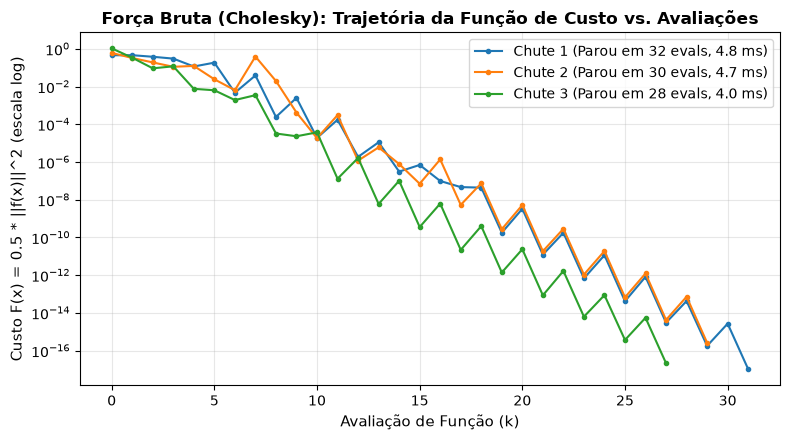

Execução     | Critério de Parada                       | Avaliações | Tempo (ms) | Fidelidade |    Resíduo
---------------------------------------------------------------------------------------------------------
Chute 1      | `gtol` termination condition is satisfied. |         32 |       4.81 |   1.000000 |   4.56e-09
Chute 2      | `gtol` termination condition is satisfied. |         30 |       4.65 |   1.000000 |   2.28e-08
Chute 3      | `gtol` termination condition is satisfied. |         28 |       3.96 |   1.000000 |   6.54e-09


In [2]:
# Reconstrução via Força Bruta e Rastreamento da Trajetória
np.random.seed(42)
unk_state = QuantState([2.0 / np.sqrt(5.0), 1.0 / np.sqrt(5.0)])
observables_1q = ["X", "Y", "Z"]
q_exatos = measure_observables(unk_state, observables_1q)

chutes = [np.random.randn(4) for _ in range(3)]
resultados_fb = []

plt.figure(figsize=(8, 4.5))

for idx, x0 in enumerate(chutes):
    res = solve_tomography(observables_1q, q_exatos, method="least_squares",
                           chute_inicial=x0, true_state=unk_state, n_qubits=1)
    resultados_fb.append(res)
    custos = res.extra["cost_history"]
    plt.semilogy(custos, "o-", markersize=3, label=f"Chute {idx+1} (Parou em {res.num_iters} evals, {res.elapsed_seconds*1000:.1f} ms)")

plt.title("Força Bruta (Cholesky): Trajetória da Função de Custo vs. Avaliações", fontsize=12, fontweight="bold")
plt.xlabel("Avaliação de Função (k)", fontsize=11)
plt.ylabel("Custo F(x) = 0.5 * ||f(x)||^2 (escala log)", fontsize=11)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=10)
plt.tight_layout()
plt.show()

print(f"{'Execução':<12s} | {'Critério de Parada':<40s} | {'Avaliações':>10s} | {'Tempo (ms)':>10s} | {'Fidelidade':>10s} | {'Resíduo':>10s}")
print("-" * 105)
for i, res in enumerate(resultados_fb):
    print(f"Chute {i+1:<6d} | {res.status:<40s} | {res.num_iters:10d} | {res.elapsed_seconds*1000:10.2f} | {res.fidelity:10.6f} | {res.residual:10.2e}")


In [3]:
print(np.trace(resultados_fb[2].rho@qt.sigma_x), np.trace(resultados_fb[2].rho@qt.sigma_y), np.trace(resultados_fb[2].rho@qt.sigma_z))

(0.7999999952558244+0j) (2.4382414879412818e-32+0j) (0.6000000045010875+0j)


--- Estados Reconstruídos por Força Bruta com Diferentes Inicializações ---
Força Bruta A: r = [0.7   0.4   0.442] | Parada: 38 evals
Força Bruta B: r = [ 0.7    0.4   -0.568] | Parada: 33 evals
Força Bruta C: r = [ 0.7    0.4   -0.235]


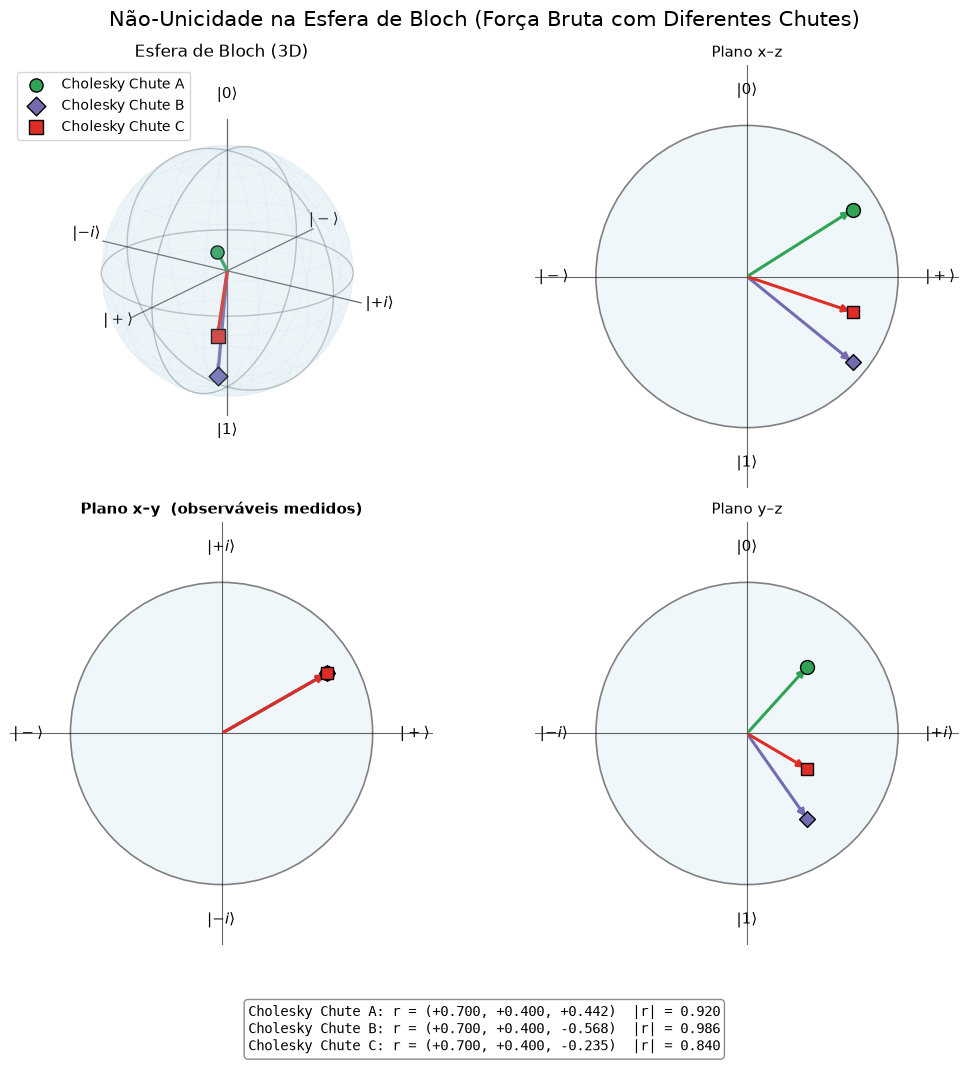

In [4]:
# Não-Unicidade com Força Bruta na Esfera de Bloch
res_uniq = qt.run_uniqueness_experiment(q_values=(0.7, 0.4), seed=42)

rho_lsq_a = res_uniq["least_squares_a"].rho
rho_lsq_b = res_uniq["least_squares_b"].rho
rho_lsq_c = solve_tomography(["X", "Y"], [0.7, 0.4], method="least_squares",
                             chute_inicial=np.random.randn(4), n_qubits=1).rho

print("--- Estados Reconstruídos por Força Bruta com Diferentes Inicializações ---")
print(f"Força Bruta A: r = {np.round(qt.vetor_bloch(rho_lsq_a), 3)} | Parada: {res_uniq['least_squares_a'].num_iters} evals")
print(f"Força Bruta B: r = {np.round(qt.vetor_bloch(rho_lsq_b), 3)} | Parada: {res_uniq['least_squares_b'].num_iters} evals")
print(f"Força Bruta C: r = {np.round(qt.vetor_bloch(rho_lsq_c), 3)}")

# Visualização na Esfera de Bloch
fig_bloch = plotar_bloch(
    [rho_lsq_a, rho_lsq_b, rho_lsq_c],
    rotulos=["Cholesky Chute A", "Cholesky Chute B", "Cholesky Chute C"],
    cores=["#31a354", "#756bb1", "#de2d26"],
    medidos=("x", "y"),
    titulo="Não-Unicidade na Esfera de Bloch (Força Bruta com Diferentes Chutes)",
    salvar="bloch_reconstrucoes.png"
)
plt.show()


In [5]:
purity_results = qt.run_purity_spectrum_experiment(
    n_qubits=2, num_measurements=6, seed=42, N_shots=10000, solvers=["least_squares"]
)

purity_results_extended = qt.run_purity_spectrum_experiment(
    n_qubits=2, num_measurements=6, seed=42, N_shots=10000
)

purity_complete = qt.run_purity_spectrum_experiment(
    n_qubits=2, measurement_completeness="complete", seed=42, N_shots=10000
)

Classe de Estado               | Fidelidade  |  Iterações | Tempo (ms)
-------------------------------------------------------------------------------------
1. Puro (Posto 1)              |     0.9610 |         31 |       4.49
2. Mistura de Puros (Posto 2)  |     0.4114 |         29 |       4.40
3. Totalmente Misto (I/d)      |     0.5546 |         26 |       3.66


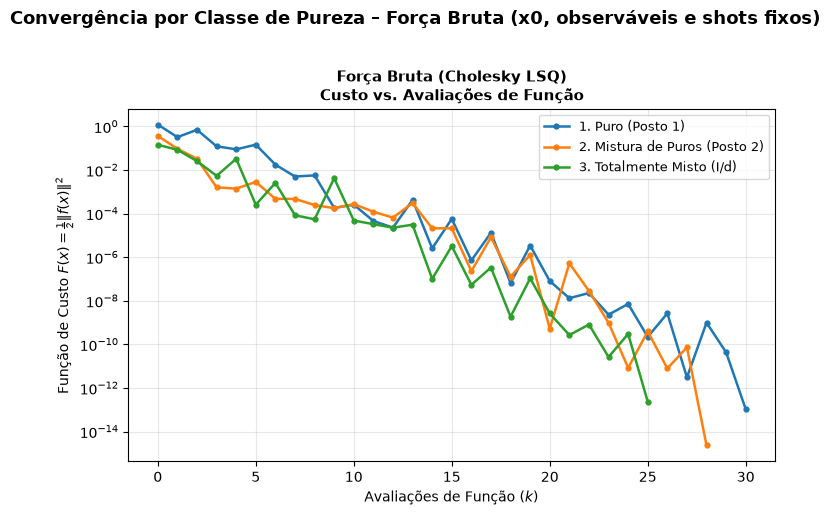

In [6]:

print(f"{'Classe de Estado':<30s} | {'Fidelidade':>10s}  | {'Iterações':>10s} | {'Tempo (ms)':>10s}")
print("-" * 85)
for state_name, solvers_res in purity_results_extended.items():
    res = solvers_res["least_squares"]
    print(f"{state_name:<30s} | {res.fidelity:10.4f} | {res.num_iters:10d} | {res.elapsed_seconds*1000:10.2f}")

fig_purity_conv = qt.plot_purity_convergence(
    purity_results_extended,
    title="Convergência por Classe de Pureza – Força Bruta (x0, observáveis e shots fixos)",
    save_path="trajetoria_custo_pureza.png",
)
plt.show()



Classe de Estado             | Medição        | Fidelidade |    Resíduo |  Iterações
-------------------------------------------------------------------------------------
1. Puro (Posto 1)            | M=6 (Incomp.)  |     0.9610 |   4.59e-07 |         31
1. Puro (Posto 1)            | M=15 (Compl.)  |     0.9970 |   1.71e-02 |         42
2. Mistura de Puros (Posto 2) | M=6 (Incomp.)  |     0.4114 |   6.78e-08 |         29
2. Mistura de Puros (Posto 2) | M=15 (Compl.)  |     0.9977 |   1.98e-02 |        102
3. Totalmente Misto (I/d)    | M=6 (Incomp.)  |     0.5546 |   6.83e-07 |         26
3. Totalmente Misto (I/d)    | M=15 (Compl.)  |     0.9995 |   7.81e-09 |         37


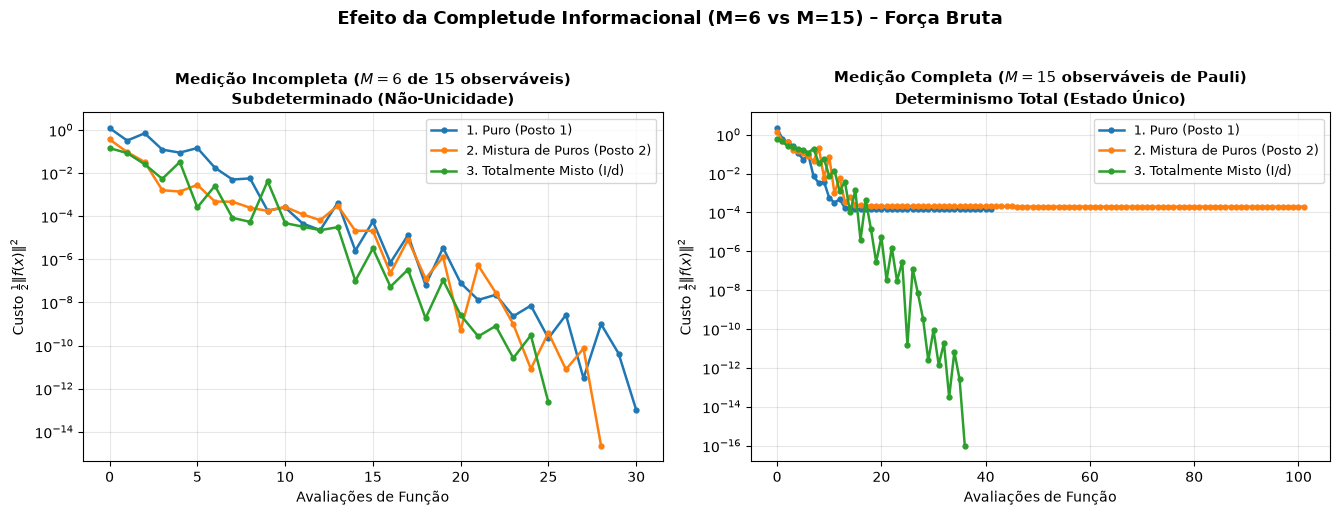

In [7]:
# Medição incompleta (M=6) vs. completa (M=15) ---


print(f"{'Classe de Estado':<28s} | {'Medição':<14s} | {'Fidelidade':>10s} | {'Resíduo':>10s} | {'Iterações':>10s}")
print("-" * 85)
for state_name in purity_results_extended:
    for m_label, exp_set in [("M=6 (Incomp.)", purity_results_extended), ("M=15 (Compl.)", purity_complete)]:
        res = exp_set[state_name]["least_squares"]
        print(f"{state_name:<28s} | {m_label:<14s} | {res.fidelity:10.4f} | {res.residual:10.2e} | {res.num_iters:10d}")

fig_comp = qt.plot_purity_completeness_comparison(
    purity_results_extended, purity_complete,
    title="Efeito da Completude Informacional (M=6 vs M=15) – Força Bruta",
    save_path="pureza_completa_vs_incompleta.png",
)
plt.show()


Executando simulação de estabilidade e ruído de shot noise...


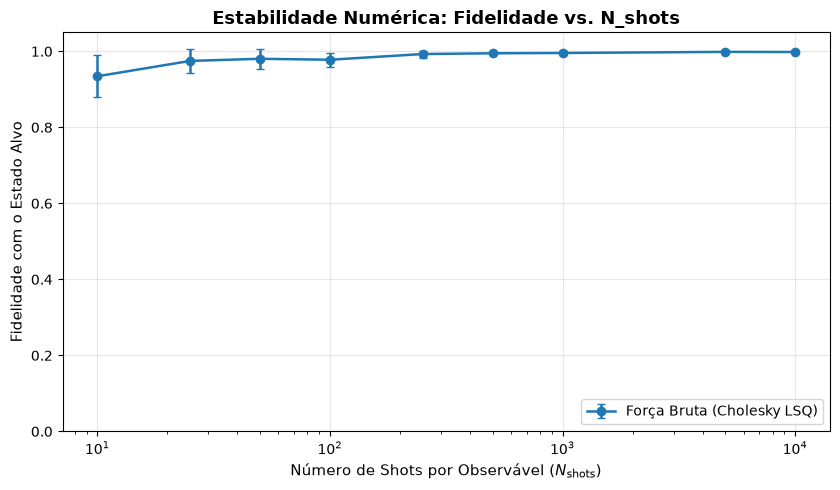

N_shots     | Fidelidade (Força Bruta)  
------------------------------------------------------------------------------------------------------
10                |   0.9344 +- 0.0547       %
25                |   0.9747 +- 0.0324       %
50                |   0.9804 +- 0.0268       %
100               |   0.9779 +- 0.0180       %
250               |   0.9929 +- 0.0091       %
500               |   0.9949 +- 0.0054       %
1000              |   0.9957 +- 0.0055       %
5000              |   0.9986 +- 0.0018       %
10000             |   0.9983 +- 0.0026       %


In [8]:
# Estabilidade perante Ruído de Shot Noise
print("Executando simulação de estabilidade e ruído de shot noise...")
shots_teste = [10, 25, 50, 100, 250, 500, 1000, 5000, 10000]
noise_data = qt.run_noise_stability_experiment(
    n_qubits=1,
    shots_list=shots_teste,
    n_reps=20,
    seed=42
)

fig_noise = plot_fidelity_vs_shots(
    shots_list=noise_data["shots_list"],
    fidelidades_medias={    
        "Força Bruta (Cholesky LSQ)": noise_data["fids_brute_force"]
    },
    fidelidades_stds={
        "Força Bruta (Cholesky LSQ)": noise_data["stds_brute_force"]
    },
    title="Estabilidade Numérica: Fidelidade vs. N_shots",
    save_path="ruido_shot_noise_sdp.png"
)
plt.show()

print(f"{'N_shots':<10s}  | {'Fidelidade (Força Bruta)':<26s}")
print("-" * 102)
for i, shots in enumerate(noise_data["shots_list"]):
    fid_bf = noise_data["fids_brute_force"][i]
    std_bf = noise_data["stds_brute_force"][i]

    print(f"{shots:<10d}        | {fid_bf:8.4f} +- {std_bf:6.4f}       %")


Executando benchmark de escalabilidade com shots reais (N_shots=10.000, 5 repetições por qubit)...


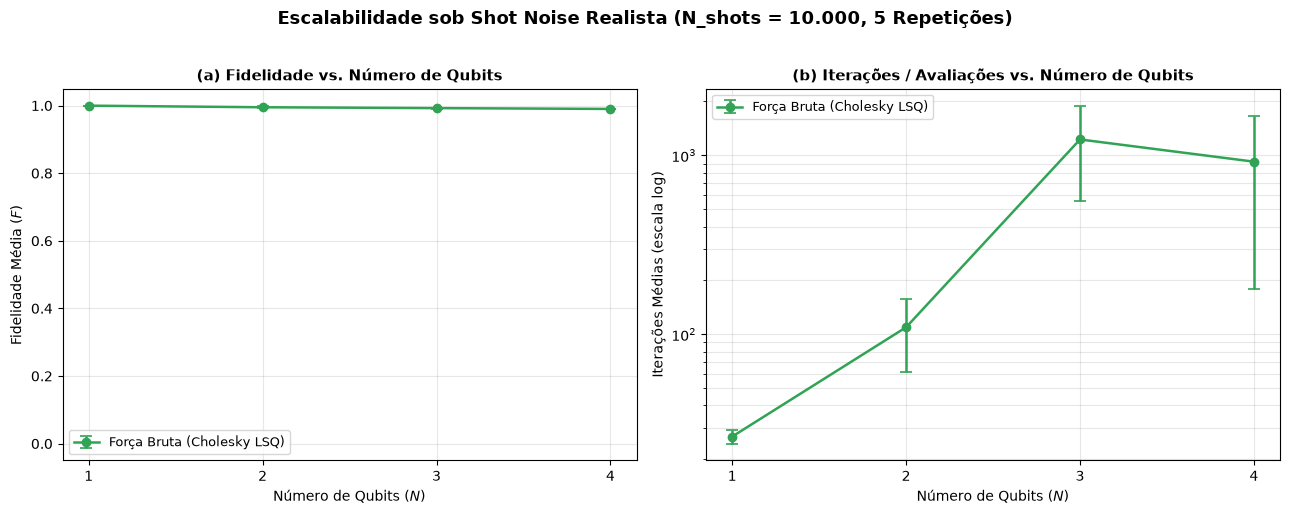

Qubits   | Dim    | Obs (4^N-1)  | Método                     | Fidelidade Média     | Iterações Médias     | Tempo Médio (s) 
-------------------------------------------------------------------------------------------------------------------
1        | 2      | 3            | Força Bruta (Cholesky)     | 0.9998 +- 0.0002     |   26.8 +-   2.3      | 0.0037s         
-------------------------------------------------------------------------------------------------------------------
2        | 4      | 15           | Força Bruta (Cholesky)     | 0.9950 +- 0.0026     |  109.4 +-  47.7      | 0.0183s         
-------------------------------------------------------------------------------------------------------------------
3        | 8      | 63           | Força Bruta (Cholesky)     | 0.9925 +- 0.0016     | 1226.4 +- 670.3      | 1.3880s         
-------------------------------------------------------------------------------------------------------------------
4        | 16     | 255     

In [9]:
# Benchmark de Escalabilidade com Shots Reais (N = 1 a 4)
print("Executando benchmark de escalabilidade com shots reais (N_shots=10.000, 5 repetições por qubit)...")

benchmark_shots_data = qt.run_shots_scaling_benchmark(
    qubits_range=[1, 2, 3, 4
                  ],
    n_shots=10000,
    methods=["least_squares"],
    n_reps=5,
    seed=42,
    max_iter_quadratic=300
)


fig_shots_scale = qt.plot_shots_scaling(
    benchmark_shots_data,
    title="Escalabilidade sob Shot Noise Realista (N_shots = 10.000, 5 Repetições)",
    save_path="benchmark_shots_scaling.png"
)
plt.show()


print(f"{'Qubits':<8s} | {'Dim':<6s} | {'Obs (4^N-1)':<12s} | {'Método':<26s} | {'Fidelidade Média':<20s} | {'Iterações Médias':<20s} | {'Tempo Médio (s)':<16s}")
print("-" * 115)
for i, n in enumerate(benchmark_shots_data["qubits_range"]):
    dim = 2 ** n
    n_obs = 4 ** n - 1
    for m in benchmark_shots_data["methods"]:
        nome_m = "Força Bruta (Cholesky)" if m == "least_squares" else "SDP Dual (Quadrático)"
        f_mean = benchmark_shots_data["fidelidades_mean"][m][i]
        f_std = benchmark_shots_data["fidelidades_std"][m][i]
        it_mean = benchmark_shots_data["iteracoes_mean"][m][i]
        it_std = benchmark_shots_data["iteracoes_std"][m][i]
        t_mean = benchmark_shots_data["tempos_mean"][m][i]
        t_std = benchmark_shots_data["tempos_std"][m][i]
        
        fid_str = f"{f_mean:.4f} +- {f_std:.4f}"
        it_str = f"{it_mean:6.1f} +- {it_std:5.1f}"
        t_str = f"{t_mean:.4f}s"
        print(f"{n:<8d} | {dim:<6d} | {n_obs:<12d} | {nome_m:<26s} | {fid_str:<20s} | {it_str:<20s} | {t_str:<16s}")
    print("-" * 115)


In [10]:
# Reconstrução Palpável do Estado W de 3 Qubits com Shots Reais
print("--- Reconstrução Palpável: Estado W de 3 Qubits com N_shots = 10.000 ---")

target_w3 = qt.standard_pure_state("w", n_qubits=3)
all_obs_3q = qt.pauli_basis_strings(3)
q_exato_3q = qt.measure_observables(target_w3, all_obs_3q)

rng_w3 = np.random.default_rng(42)
q_shots_3q = qt.simula_medidas_shots(q_exato_3q, 10000, rng=rng_w3)

t0 = time.time()
res_w3 = qt.solve_tomography(all_obs_3q, q_shots_3q, method="least_squares", true_state=target_w3, n_qubits=3)
tempo_w3 = time.time() - t0


print(f"\n{'Sistema':<18s} | {'Estado Alvo':<25s} | {'Fidelidade':>12s} | {'Avaliações':>12s} | {'Tempo (s)':>12s} | {'Resíduo':>12s}")
print("-" * 102)
print(f"{'3 Qubits (dim=8)':<18s} | {'Estado W (|100>+|010>+|001>)/√3':<25s} | {res_w3.fidelity:12.6f} | {res_w3.num_iters:12d} | {tempo_w3:12.4f} | {res_w3.residual:12.2e}")


--- Reconstrução Palpável: Estado W de 3 Qubits com N_shots = 10.000 ---

Sistema            | Estado Alvo               |   Fidelidade |   Avaliações |    Tempo (s) |      Resíduo
------------------------------------------------------------------------------------------------------
3 Qubits (dim=8)   | Estado W (|100>+|010>+|001>)/√3 |     0.993060 |         6400 |       6.8486 |     6.13e-02
